> ℹ️ **NOTE: This program runs on IBM Quantum Cloud, not the local emulator.**
> 
> This notebook submits the QAOA circuit to the [IBM Quantum](https://quantum.cloud.ibm.com) platform rather than running on a local simulator. An IBM Quantum account and valid API token are required.

## QAOA Batch Job Scheduler — IBM Quantum Cloud

This notebook solves the IBM i batch job scheduling problem using **QAOA** running on a real IBM Quantum device. Job data is fetched from IBM i via Mapepire, the optimised schedule is decoded from quantum measurement results, and the result is written back to IBM i.

**Changes from the local simulator version (`qaoa_scheduler.ipynb`):**
- Uses `QiskitRuntimeService` instead of `AerSimulator`
- Uses `SamplerV2` primitive + `generate_preset_pass_manager` for transpilation
- Prompts for the IBM Quantum API key securely at runtime (masked input, never stored)
- Prints Job ID and IBM Quantum tracking URL after submission
- COBYLA optimisation uses direct job-mode `SamplerV2` calls (open plan compatible — no `Session` required)

**Author:** Quantum-IBMi-Docker Project | Het Patel

### Import Required Libraries

In [1]:
import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from typing import List, Dict, Tuple
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

from mapepire_python.client.sql_job import SQLJob
from mapepire_python.data_types import DaemonServer
from IPython.display import Markdown, display

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


### Connect to IBM i via Mapepire

In [2]:
host = input("Enter IBM i hostname/IP: ").strip()
username = input("Enter username: ").strip()
password = getpass.getpass("Enter password: ")
port_input = input("Enter port (press Enter for default 8076): ").strip()
port = int(port_input) if port_input else 8076

daemon_server = DaemonServer(host=host, port=port, user=username, password=password)
sql_job = SQLJob()
sql_job.connect(daemon_server)

display(Markdown("**✓ Connected to IBM i database**"))

Enter IBM i hostname/IP:  idevphp.idevcloud.com
Enter username:  Jgorzins
Enter password:  ········
Enter port (press Enter for default 8076):  


**✓ Connected to IBM i database**

### Connect to IBM Quantum

Your API key is entered securely below (input is masked, like a password).
The key is never written to disk or stored in the notebook.

See the [IBM Quantum API Key](#ibm-quantum-api-key) section in [`README.md`](README.md) for instructions on finding your key.

To target a specific device instead of the least-busy one, replace the last line with:
```python
backend = service.backend("ibm_brisbane")
```
To use the cloud QASM simulator instead of real hardware:
```python
backend = service.least_busy(simulator=True)
```

In [3]:
# Prompt for the IBM Quantum API key (input is masked - never stored in notebook)
ibm_token = getpass.getpass("Enter IBM Quantum API key: ")

service = QiskitRuntimeService(channel="ibm_quantum_platform", token=ibm_token)

backend = service.least_busy(simulator=False, operational=True)
print(f"✓ Connected to backend: {backend.name}")
print(f"  Qubits available: {backend.num_qubits}")

Enter IBM Quantum API key:  ········


qiskit_runtime_service._discover_account:WARNING:2026-09-22 17:36:52,955: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-09-22 17:36:58,608: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-09-22 17:36:59,155: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-09-22 17:37:03,213: Using instance: open-instance, plan: open


✓ Connected to backend: ibm_fez
  Qubits available: 156


### Fetch Job Queue from IBM i

Queries `QSCHEDULE.JOBQUEUE()` — the table function created by `dbsetup.ipynb`.
Each row is a batch job with duration, priority, memory requirement, and dependency.

In [4]:
query = sql_job.query(
    "SELECT * FROM TABLE(QSCHEDULE.JOBQUEUE()) AS t ORDER BY JOB_ID"
)
result = query.run()

if not result.get("success") or not result.get("data"):
    raise Exception(f"Query failed: {result.get('error', 'No data returned')}")

jobs = result["data"]
df_jobs = pd.DataFrame(jobs)

print(f"✓ Loaded {len(jobs)} jobs from QSCHEDULE.JOBQUEUE()\n")
display(df_jobs)

✓ Loaded 8 jobs from QSCHEDULE.JOBQUEUE()



,JOB_ID,JOB_NAME,DURATION,PRIORITY,MEM_MB,DEPENDS_ON
0,1,PAYROLL,45,1,512,0
1,2,INVUPD,20,2,256,0
2,3,GLCLOSE,60,1,768,1
3,4,ARAGING,30,3,256,2
4,5,SALESRPT,15,4,128,0
5,6,BACKUPDB,90,5,128,3
6,7,TAXCALC,35,1,512,1
7,8,SHIPCONF,10,2,128,0


### Build QUBO Cost Matrix

The scheduling QUBO encodes:
- **One-hot constraint**: each job must be assigned exactly one time slot
- **Priority reward**: earlier slots for higher-priority jobs lower the cost
- **Dependency penalty**: if job A depends on job B, A in an earlier slot than B is heavily penalised
- **Memory constraint**: jobs in the same slot cannot exceed the total memory pool (2048 MB)

Binary variable x_{i,s} = 1 means job i is assigned to slot s.

**Penalty weight rationale:**
- `penalty_one_hot = 8.0` — each job must occupy exactly one slot; kept slightly below dependency penalty
- `penalty_dependency = 80.0` — must dominate all other terms so violations are decisively expensive;
  a single dependency violation adds ~238 to the cost vs the ideal feasible schedule
- `penalty_memory = 10.0` — penalises pairs of jobs that together exceed 2048 MB in the same slot

In [5]:
def build_qubo(
    jobs: List[Dict],
    num_slots: int = 4,
    penalty_one_hot: float = 8.0,
    penalty_dependency: float = 80.0,
    penalty_memory: float = 10.0,
    memory_pool_mb: int = 2048,
) -> Tuple[np.ndarray, List[str]]:
    """
    Build a QUBO matrix Q for the job scheduling problem.
    Binary variables x_{i,s}: 1 if job i is in slot s, else 0.
    Variable ordering: x_{0,0}, x_{0,1}, ..., x_{0,S-1}, x_{1,0}, ...

    One-hot formulation (exact-one constraint):
      cost = penalty * (1 - sum_s x_{i,s})^2
    Expanding gives diagonal -2*penalty (rewards assignment) and off-diagonal
    +2*penalty (penalises double-assignment). Zero-assignment gets no reward,
    so it costs +2*penalty more than a valid single-slot assignment.
    """
    n_jobs = len(jobs)
    n_vars = n_jobs * num_slots
    Q = np.zeros((n_vars, n_vars))
    labels = [f"{jobs[i]['JOB_NAME']}_s{s}" for i in range(n_jobs) for s in range(num_slots)]

    def idx(job_i, slot_s):
        return job_i * num_slots + slot_s

    # 1. Priority reward: penalise assigning high-priority jobs to late slots
    for i, job in enumerate(jobs):
        for s in range(num_slots):
            cost = (job["PRIORITY"] == 1) * s * 2.0 + job["DURATION"] * 0.1
            Q[idx(i, s), idx(i, s)] += cost

    # 2. One-hot constraint: each job assigned to EXACTLY one slot.
    # Diagonal -2*penalty rewards assignment; zero-assignment costs +2*penalty more.
    # Off-diagonal +2*penalty penalises assigning the same job to two slots.
    for i in range(n_jobs):
        for s in range(num_slots):
            Q[idx(i, s), idx(i, s)] -= 2 * penalty_one_hot
        for s1, s2 in combinations(range(num_slots), 2):
            Q[idx(i, s1), idx(i, s2)] += 2 * penalty_one_hot

    # 3. Dependency penalty: job i depends on job d => i cannot be in same or earlier slot
    job_id_to_idx = {job["JOB_ID"]: k for k, job in enumerate(jobs)}
    for i, job in enumerate(jobs):
        dep_id = job["DEPENDS_ON"]
        if dep_id == 0:
            continue
        d = job_id_to_idx.get(dep_id)
        if d is None:
            continue
        for s_i in range(num_slots):
            for s_d in range(num_slots):
                if s_i <= s_d:
                    Q[idx(i, s_i), idx(d, s_d)] += penalty_dependency

    # 4. Memory constraint: jobs in the same slot should not exceed memory pool
    for s in range(num_slots):
        for i, j in combinations(range(n_jobs), 2):
            combined_mem = jobs[i]["MEM_MB"] + jobs[j]["MEM_MB"]
            if combined_mem > memory_pool_mb:
                Q[idx(i, s), idx(j, s)] += penalty_memory * (combined_mem / memory_pool_mb)

    return Q, labels


NUM_SLOTS = 4
Q, var_labels = build_qubo(jobs, num_slots=NUM_SLOTS)
n_qubits = len(var_labels)

print(f"✓ QUBO matrix built: {n_qubits} binary variables ({len(jobs)} jobs × {NUM_SLOTS} slots)")
print(f"  Variables: {var_labels}")

✓ QUBO matrix built: 32 binary variables (8 jobs × 4 slots)
  Variables: ['PAYROLL_s0', 'PAYROLL_s1', 'PAYROLL_s2', 'PAYROLL_s3', 'INVUPD_s0', 'INVUPD_s1', 'INVUPD_s2', 'INVUPD_s3', 'GLCLOSE_s0', 'GLCLOSE_s1', 'GLCLOSE_s2', 'GLCLOSE_s3', 'ARAGING_s0', 'ARAGING_s1', 'ARAGING_s2', 'ARAGING_s3', 'SALESRPT_s0', 'SALESRPT_s1', 'SALESRPT_s2', 'SALESRPT_s3', 'BACKUPDB_s0', 'BACKUPDB_s1', 'BACKUPDB_s2', 'BACKUPDB_s3', 'TAXCALC_s0', 'TAXCALC_s1', 'TAXCALC_s2', 'TAXCALC_s3', 'SHIPCONF_s0', 'SHIPCONF_s1', 'SHIPCONF_s2', 'SHIPCONF_s3']


### Convert QUBO to Ising Hamiltonian

QAOA operates on an Ising Hamiltonian expressed as a `SparsePauliOp`.
The substitution x_i = (1 - Z_i) / 2 converts the QUBO into Z-basis Pauli terms.

In [6]:
def qubo_to_ising(Q: np.ndarray) -> SparsePauliOp:
    """
    Convert QUBO matrix Q to an Ising cost Hamiltonian as SparsePauliOp.
    Uses x_i = (1 - Z_i)/2 substitution.
    """
    n = Q.shape[0]
    pauli_list = []

    for i in range(n):
        for j in range(i, n):
            if abs(Q[i, j]) < 1e-10:
                continue
            coeff = Q[i, j] if i == j else Q[i, j] / 2  # symmetrise off-diagonal

            if i == j:
                # Q_ii * x_i -> Q_ii/2 * (I - Z_i)
                # Constant term dropped; Z_i term added
                z_str = ["I"] * n
                z_str[i] = "Z"
                pauli_list.append(("".join(reversed(z_str)), -coeff / 2))
            else:
                # Q_ij * x_i * x_j -> Q_ij/4 * (I - Z_i - Z_j + Z_i Z_j)
                # Only ZZ and single-Z terms contribute (constants dropped)
                zz_str = ["I"] * n
                zz_str[i] = "Z"
                zz_str[j] = "Z"
                pauli_list.append(("".join(reversed(zz_str)), coeff / 4))

                zi_str = ["I"] * n
                zi_str[i] = "Z"
                pauli_list.append(("".join(reversed(zi_str)), -coeff / 4))

                zj_str = ["I"] * n
                zj_str[j] = "Z"
                pauli_list.append(("".join(reversed(zj_str)), -coeff / 4))

    if not pauli_list:
        raise ValueError("Empty Hamiltonian — check QUBO matrix")

    return SparsePauliOp.from_list(pauli_list).simplify()


cost_hamiltonian = qubo_to_ising(Q)
print(f"✓ Ising Hamiltonian built")
print(f"  Number of Pauli terms: {len(cost_hamiltonian)}")
print(f"  Number of qubits     : {cost_hamiltonian.num_qubits}")

✓ Ising Hamiltonian built
  Number of Pauli terms: 80
  Number of qubits     : 32


### Build and Transpile QAOA Circuit

QAOA with `p=QAOA_LAYERS` layers consists of:
1. Equal superposition via H gates on all qubits
2. Cost layer: `e^{-i γ H_C}` — encodes the cost Hamiltonian
3. Mixer layer: `e^{-i β H_M}` — Rx rotations drive exploration
4. Measure all qubits

The circuit is transpiled with `generate_preset_pass_manager` (optimization level 3)
to target the selected backend's native gate set and qubit topology.

In [8]:
def build_qaoa_circuit(cost_op: SparsePauliOp, p: int = 1) -> QuantumCircuit:
    """
    Build a QAOA circuit with p layers.
    Returns a parameterised circuit with 2*p parameters: [gamma_0,...,gamma_{p-1}, beta_0,...,beta_{p-1}]
    """
    n = cost_op.num_qubits
    gamma = ParameterVector("γ", p)
    beta  = ParameterVector("β", p)

    qc = QuantumCircuit(n, n)

    # Initial state: uniform superposition
    qc.h(range(n))

    for layer in range(p):
        # Cost unitary: e^{-i gamma * H_C}
        for pauli_str, coeff in zip(
            [str(p_op) for p_op in cost_op.paulis],
            cost_op.coeffs
        ):
            angle = 2 * gamma[layer] * float(coeff.real)
            z_indices = [i for i, c in enumerate(reversed(pauli_str)) if c == "Z"]
            if len(z_indices) == 1:
                qc.rz(angle, z_indices[0])
            elif len(z_indices) == 2:
                qc.cx(z_indices[0], z_indices[1])
                qc.rz(angle, z_indices[1])
                qc.cx(z_indices[0], z_indices[1])

        # Mixer unitary: e^{-i beta * H_M} where H_M = sum_i X_i
        for i in range(n):
            qc.rx(2 * beta[layer], i)

    qc.measure(range(n), range(n))
    return qc


QAOA_LAYERS = 4
qaoa_circuit = build_qaoa_circuit(cost_hamiltonian, p=QAOA_LAYERS)

print(f"✓ QAOA circuit built")
print(f"  Qubits         : {qaoa_circuit.num_qubits}")
print(f"  QAOA layers    : {QAOA_LAYERS}")
print(f"  Parameters     : {[str(p) for p in qaoa_circuit.parameters]}")
print(f"  Circuit depth  : {qaoa_circuit.depth()}")

# Transpile for target backend
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_circuit = pm.run(qaoa_circuit)

print(f"\n✓ Circuit transpiled for {backend.name}")
print(f"  Transpiled depth  : {isa_circuit.depth()}")
print(f"  Transpiled qubits : {isa_circuit.num_qubits}")

✓ QAOA circuit built
  Qubits         : 32
  QAOA layers    : 4
  Parameters     : ['β[0]', 'β[1]', 'β[2]', 'β[3]', 'γ[0]', 'γ[1]', 'γ[2]', 'γ[3]']
  Circuit depth  : 62

✓ Circuit transpiled for ibm_fez
  Transpiled depth  : 335
  Transpiled qubits : 156


### Optimise QAOA Parameters via IBM Quantum Runtime

COBYLA minimises the expected QUBO cost by repeatedly evaluating the QAOA circuit.
Each evaluation submits a job directly to IBM Quantum via `SamplerV2(backend)` — **no `Session` required**.
This job-mode execution is compatible with the IBM Quantum open (free) plan.

> ⚠️ **Note:** COBYLA with 100 iterations submits up to 100 individual quantum jobs.
> On a real device this may take significant queue time. Reduce `maxiter` for faster
> (less optimal) results, or use `simulator=True` when selecting the backend above.

In [ ]:
SHOTS = 1024


def compute_cost_from_counts(counts: Dict[str, int], Q: np.ndarray) -> float:
    """Evaluate the QUBO cost E[x^T Q x] from measurement counts."""
    total_shots = sum(counts.values())
    total_cost = 0.0
    for bitstring, count in counts.items():
        x = np.array([int(b) for b in reversed(bitstring)], dtype=float)
        cost = x @ Q @ x
        total_cost += cost * count
    return total_cost / total_shots


def get_counts_from_sampler_result(result) -> Dict[str, int]:
    """Extract a counts dict {bitstring: count} from a SamplerV2 PubResult."""
    pub_result = result[0]
    counts = {}
    for bitstring, count in pub_result.data.c.get_counts().items():
        counts[bitstring] = count
    return counts


# Job-mode execution: create one Sampler per call — no Session needed (open plan compatible)
print(f"Optimising QAOA parameters with COBYLA ({SHOTS} shots per evaluation)...")
print(f"Backend: {backend.name}")
print("This may take several minutes depending on queue depth.\n")


def objective(params: np.ndarray) -> float:
    """Bind parameters, submit to IBM Quantum (job mode), return expected QUBO cost."""
    sampler = Sampler(backend)
    sampler.options.default_shots = SHOTS
    param_dict = dict(zip(isa_circuit.parameters, params))
    bound_circuit = isa_circuit.assign_parameters(param_dict)
    job = sampler.run([bound_circuit])
    counts = get_counts_from_sampler_result(job.result())
    return compute_cost_from_counts(counts, Q)


init_params = np.array([0.5, 0.5] * QAOA_LAYERS)  # [gamma_0, beta_0]

opt_result = minimize(
    objective,
    init_params,
    method="COBYLA",
    options={"maxiter": 50, "rhobeg": 0.5},
)

optimal_params = opt_result.x
print(f"\n✓ Optimisation complete")
print(f"  Optimal γ  : {optimal_params[:QAOA_LAYERS]}")
print(f"  Optimal β  : {optimal_params[QAOA_LAYERS:]}")
print(f"  Final cost : {opt_result.fun:.4f}")
print(f"  Iterations : {opt_result.nfev}")

Optimising QAOA parameters with COBYLA (1024 shots per evaluation)...
Backend: ibm_fez
This may take several minutes depending on queue depth.



### Sample Final Circuit with Optimal Parameters

Run one final job on IBM Quantum with the optimal `γ` and `β` values.
The Job ID and tracking URL are printed so results can be retrieved later.

In [11]:
param_dict = dict(zip(isa_circuit.parameters, optimal_params))
final_circuit = isa_circuit.assign_parameters(param_dict)

# Direct job-mode submission — no Session required (open plan compatible)
sampler = Sampler(backend)
sampler.options.default_shots = SHOTS
final_job = sampler.run([final_circuit])

print(f"✓ Final job submitted")
print(f"  Job ID      : {final_job.job_id()}")
print(f"  Tracking URL: https://quantum.cloud.ibm.com/jobs/{final_job.job_id()}")
print(f"  Waiting for results...")

final_result = final_job.result()

counts = get_counts_from_sampler_result(final_result)

# QUBO cost helper (needed for feasibility-filtered selection)
def qubo_cost(bitstring: str) -> float:
    x = np.array([int(b) for b in reversed(bitstring)], dtype=float)
    return float(x @ Q @ x)

def is_feasible(bitstring: str, n_jobs: int, num_slots: int) -> bool:
    """Return True only if every job group has at least one assigned slot."""
    bits = [int(b) for b in reversed(bitstring)]
    for i in range(n_jobs):
        job_bits = bits[i * num_slots:(i + 1) * num_slots]
        if sum(job_bits) == 0:
            return False
    return True

n_jobs_val = len(jobs)
feasible_candidates = [b for b in counts if is_feasible(b, n_jobs_val, NUM_SLOTS)]

# Most-frequent for reference
top_bitstring = max(counts, key=counts.get)
top_count = counts[top_bitstring]

if feasible_candidates:
    best_bitstring = min(feasible_candidates, key=qubo_cost)
    best_count = counts[best_bitstring]
    best_cost = qubo_cost(best_bitstring)
    print(f"\n✓ Final sampling complete")
    print(f"  Backend       : {backend.name}")
    print(f"  Most frequent : {top_bitstring}  (count {top_count})")
    print(f"  Feasible candidates: {len(feasible_candidates)} / {len(counts)}")
    print(f"  Best feasible (lowest cost): {best_bitstring}  (cost {best_cost:.2f}, count {best_count})")
    top_bitstring = best_bitstring
    top_count = best_count
else:
    best_bitstring = min(counts.keys(), key=qubo_cost)
    best_count = counts[best_bitstring]
    best_cost = qubo_cost(best_bitstring)
    print(f"\n✓ Final sampling complete")
    print(f"  Backend       : {backend.name}")
    print(f"  Most frequent : {top_bitstring}  (count {top_count})")
    print(f"  WARNING: No fully-feasible bitstring observed in {len(counts)} candidates.")
    print(f"  Using lowest-cost candidate: {best_bitstring}  (cost {best_cost:.2f})")
    print("  Consider increasing QAOA_LAYERS or penalty_one_hot.")
    top_bitstring = best_bitstring
    top_count = best_count

✓ Final job submitted
  Job ID      : dap7khv8gn2s739orc7g
  Tracking URL: https://quantum.cloud.ibm.com/jobs/dap7khv8gn2s739orc7g
  Waiting for results...

✓ Final sampling complete
  Backend       : ibm_fez
  Most frequent : 00110000000010100010110000100011  (count 1)
  Feasible candidates: 264 / 1024
  Best feasible (lowest cost): 11111000100000011000110000110111  (cost 168.50, count 1)


### Decode Bitstring to Job Schedule

Each group of `NUM_SLOTS` bits encodes one job's slot assignment (one-hot encoding).
The bit position with value 1 within each group gives the assigned slot.

In [12]:
def decode_schedule(bitstring: str, jobs: List[Dict], num_slots: int) -> Tuple[Dict, Dict]:
    """
    Decode a QAOA bitstring into a job schedule.
    Returns (schedule, job_slots) where:
      schedule  : {slot_index: [job_names]}
      job_slots : {job_name: slot_index or None}
    A job with all-zero slot bits is marked as None (unassigned) rather than
    silently placed in slot 0, preventing false dependency violations.
    """
    bits = [int(b) for b in reversed(bitstring)]
    schedule = {s: [] for s in range(num_slots)}
    job_slots = {}

    for i, job in enumerate(jobs):
        job_bits = bits[i * num_slots:(i + 1) * num_slots]
        assigned_slot = next((s for s, b in enumerate(job_bits) if b == 1), None)
        if assigned_slot is not None:
            schedule[assigned_slot].append(job["JOB_NAME"])
        job_slots[job["JOB_NAME"]] = assigned_slot

    return schedule, job_slots


def compute_makespan(jobs: List[Dict], job_slots: Dict[str, int], num_slots: int) -> int:
    """Estimate total makespan: sum of max durations per slot (skips unassigned jobs)."""
    slot_durations = {s: 0 for s in range(num_slots)}
    for job in jobs:
        slot = job_slots.get(job["JOB_NAME"])
        if slot is not None:
            slot_durations[slot] = max(slot_durations[slot], job["DURATION"])
    return sum(slot_durations.values())


schedule, job_slots = decode_schedule(top_bitstring, jobs, NUM_SLOTS)
makespan = compute_makespan(jobs, job_slots, NUM_SLOTS)

unassigned = [j["JOB_NAME"] for j in jobs if job_slots.get(j["JOB_NAME"]) is None]

print("\n" + "=" * 60)
print("QAOA JOB SCHEDULING RESULTS — IBM QUANTUM CLOUD")
print("=" * 60)
print(f"\nBackend       : {backend.name}")
print(f"Top bitstring : {top_bitstring}")
print(f"QAOA layers   : {QAOA_LAYERS}")
if unassigned:
    print(f"  WARNING: {len(unassigned)} job(s) unassigned by circuit: {unassigned}")
print(f"Estimated makespan: {makespan} minutes\n")
print("Optimised Schedule:")
for slot in range(NUM_SLOTS):
    jobs_in_slot = schedule[slot]
    slot_mem = sum(j["MEM_MB"] for j in jobs if j["JOB_NAME"] in jobs_in_slot)
    print(f"  Slot {slot+1}: {jobs_in_slot if jobs_in_slot else '(empty)'}  "
          f"[mem: {slot_mem} MB]")
if unassigned:
    print(f"  UNASSIGNED: {unassigned}")

print()
# Dependency validation — handles None (unassigned) slots explicitly
print("Dependency check:")
all_ok = True
for job in jobs:
    dep_id = job["DEPENDS_ON"]
    my_slot = job_slots.get(job["JOB_NAME"])
    if dep_id == 0:
        if my_slot is None:
            print(f"  {job['JOB_NAME']:<12}: no dependency — UNASSIGNED ✗")
            all_ok = False
        else:
            print(f"  {job['JOB_NAME']:<12}: no dependency ✓")
        continue
    dep_job = next((j for j in jobs if j["JOB_ID"] == dep_id), None)
    if dep_job is None:
        continue
    dep_slot = job_slots.get(dep_job["JOB_NAME"])
    if my_slot is None or dep_slot is None:
        my_label  = "UNASSIGNED" if my_slot  is None else f"slot {my_slot+1}"
        dep_label = "UNASSIGNED" if dep_slot is None else f"slot {dep_slot+1}"
        print(f"  {job['JOB_NAME']:<12}: after {dep_job['JOB_NAME']} "
              f"({dep_label} \u2192 {my_label}) \u2717 VIOLATION (UNASSIGNED)")
        all_ok = False
        continue
    ok = my_slot > dep_slot
    status = "\u2713" if ok else "\u2717 VIOLATION"
    if not ok:
        all_ok = False
    print(f"  {job['JOB_NAME']:<12}: after {dep_job['JOB_NAME']} "
          f"(slot {dep_slot+1} \u2192 slot {my_slot+1}) {status}")

print()
if all_ok:
    print("\u2713 All dependency constraints satisfied")
else:
    print("\u2717 Some dependency constraints violated — consider increasing QAOA_LAYERS or penalty weights")

print("\n" + "=" * 60)


QAOA JOB SCHEDULING RESULTS — IBM QUANTUM CLOUD

Backend       : ibm_fez
Top bitstring : 11111000100000011000110000110111
QAOA layers   : 4
Estimated makespan: 195 minutes

Optimised Schedule:
  Slot 1: ['PAYROLL', 'INVUPD', 'SALESRPT', 'SHIPCONF']  [mem: 1024 MB]
  Slot 2: (empty)  [mem: 0 MB]
  Slot 3: ['GLCLOSE']  [mem: 768 MB]
  Slot 4: ['ARAGING', 'BACKUPDB', 'TAXCALC']  [mem: 896 MB]

Dependency check:
  PAYROLL     : no dependency ✓
  INVUPD      : no dependency ✓
  GLCLOSE     : after PAYROLL (slot 1 → slot 3) ✓
  ARAGING     : after INVUPD (slot 1 → slot 4) ✓
  SALESRPT    : no dependency ✓
  BACKUPDB    : after GLCLOSE (slot 3 → slot 4) ✓
  TAXCALC     : after PAYROLL (slot 1 → slot 4) ✓
  SHIPCONF    : no dependency ✓

✓ All dependency constraints satisfied



### Write Schedule Back to IBM i

In [13]:
job_order_str = "; ".join(
    f"Slot{s+1}:{','.join(schedule[s]) if schedule[s] else 'EMPTY'}"
    for s in range(NUM_SLOTS)
)

# Truncate to 64 chars to match VARCHAR(64) column width (32-qubit circuit = 32-char string)
top_bitstring_db = top_bitstring[:64]

insert_sql = (
    "INSERT INTO QSCHEDULE.SCHEDULE_RESULTS "
    "(SOLVER_TYPE, BACKEND, QAOA_LAYERS, SHOTS, JOB_ORDER, MAKESPAN_MIN, TOP_BITSTRING, TOP_COUNT) "
    f"VALUES ('IBM_QUANTUM', '{backend.name}', {QAOA_LAYERS}, {SHOTS}, "
    f"'{job_order_str}', {makespan}, '{top_bitstring_db}', {top_count})"
)

result = sql_job.query(insert_sql).run()
if result.get("success"):
    print("✓ Schedule written to QSCHEDULE.SCHEDULE_RESULTS")
else:
    print(f"✗ Insert failed: {result.get('error', 'Unknown error')}")

✓ Schedule written to QSCHEDULE.SCHEDULE_RESULTS


### Visualise Results

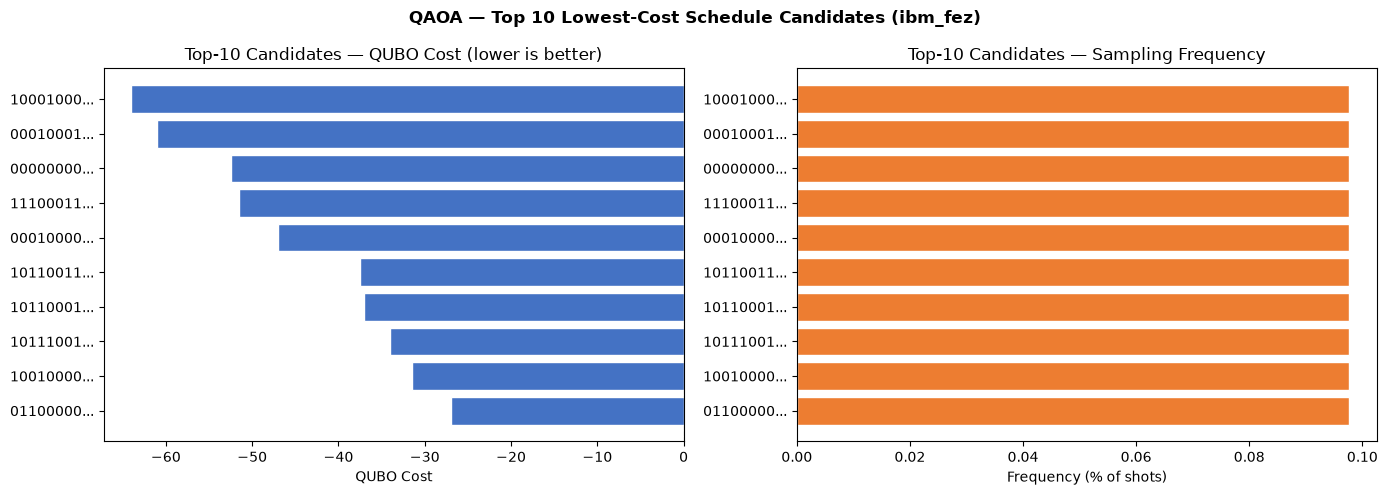

In [14]:
# Show top-10 lowest-QUBO-cost candidates (better signal than most-frequent)
# Matches the two-panel chart used in the local simulator notebook.
top_by_cost = sorted(counts.keys(), key=qubo_cost)[:10]
cost_labels = [f"{b[:8]}..." for b in top_by_cost]  # truncate 32-char strings for readability
costs  = [qubo_cost(b) for b in top_by_cost]
freqs  = [counts[b] / SHOTS * 100 for b in top_by_cost]  # as % of shots

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.barh(cost_labels[::-1], costs[::-1], color="#4472C4", edgecolor="white")
ax1.set_xlabel("QUBO Cost")
ax1.set_title("Top-10 Candidates — QUBO Cost (lower is better)")
ax1.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)

ax2.barh(cost_labels[::-1], freqs[::-1], color="#ED7D31", edgecolor="white")
ax2.set_xlabel("Frequency (% of shots)")
ax2.set_title("Top-10 Candidates — Sampling Frequency")

plt.suptitle(f"QAOA — Top 10 Lowest-Cost Schedule Candidates ({backend.name})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

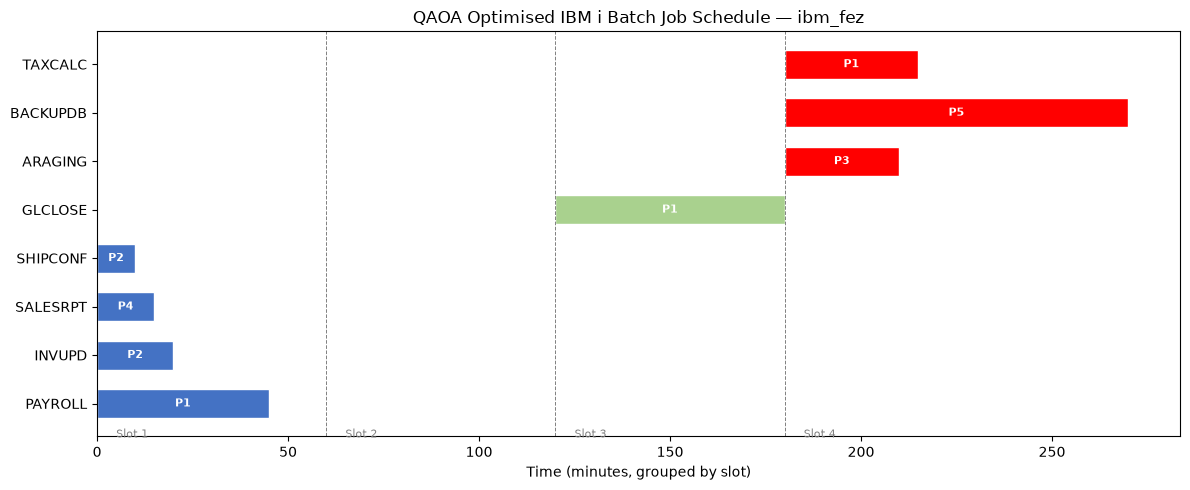

In [15]:
# Gantt-style schedule bar chart
fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#4472C4", "#ED7D31", "#A9D18E", "#FF0000"]

for job in sorted(jobs, key=lambda j: (job_slots.get(j["JOB_NAME"]) is None, job_slots.get(j["JOB_NAME"], 0))):
    slot = job_slots.get(job["JOB_NAME"])
    if slot is None:
        continue  # skip unassigned jobs in the Gantt chart
    ax.barh(
        job["JOB_NAME"],
        job["DURATION"],
        left=slot * 60,
        color=colors[slot % len(colors)],
        edgecolor="white",
        height=0.6,
    )
    ax.text(
        slot * 60 + job["DURATION"] / 2,
        job["JOB_NAME"],
        f"P{job['PRIORITY']}",
        ha="center", va="center", color="white", fontsize=8, fontweight="bold"
    )

ax.set_xlabel("Time (minutes, grouped by slot)")
ax.set_title(f"QAOA Optimised IBM i Batch Job Schedule — {backend.name}")
for s in range(NUM_SLOTS):
    ax.axvline(x=s * 60, color="grey", linestyle="--", linewidth=0.7)
    ax.text(s * 60 + 5, -0.7, f"Slot {s+1}", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

### Close Connection

In [16]:
sql_job.close()
print("✓ IBM i connection closed")

✓ IBM i connection closed
